In [1]:
# Configure every external directory here before executing the notebook.
from pathlib import Path
import os

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
RAW_DIR = Path(os.environ.get("RIDESHARE_RAW_DIR", str(PROJECT_DIR / "data/raw/fhvhv")))
PROCESSED_DIR = Path(
    os.environ.get("RIDESHARE_PROCESSED_DIR", str(PROJECT_DIR / "data/processed"))
)
ZONE_DIR = Path(
    os.environ.get("RIDESHARE_ZONE_DIR", str(PROJECT_DIR / "data/reference/taxi_zones"))
)
WEATHER_DIR = Path(
    os.environ.get(
        "RIDESHARE_WEATHER_DIR", str(PROJECT_DIR / "data/reference/weather_hourly")
    )
)
ANALYSIS_DIR = PROJECT_DIR / "outputs/demand_analysis"
# Spark users: configure JAVA_HOME and, on Windows when required, HADOOP_HOME externally.

# All directories are configured here. Hide this cell to hide local paths.
from pathlib import Path

DATA_DIR = PROCESSED_DIR
REPAIR_DIR = DATA_DIR / "repair_2024_2025"
ZONE_DIR = ZONE_DIR
RESULTS_DIR = ANALYSIS_DIR
YEARS = [2021, 2022, 2023, 2024, 2025]
# Read validated repair candidates in place; never promote or overwrite originals.
USE_VALIDATED_REPAIRS = True
SAVE_FIGURES = True


# Temporal patterns in pickup demand

## Scope and interpretation

This analysis uses cleaned **pickup totals from January 2021 through December 2025**, across all recorded HVFHV platforms. It describes observed trip activity, not requests, vehicle supply, duration or a causal policy effect. All 60 monthly inputs must pass coverage checks before cross-year comparisons. Calendar-day exposure is used for normalized volume; missing inputs are never interpreted as zero demand. Local hour labels combine repeated daylight-saving hours.

All directories are configured in the first code cell. The map joins on LocationID and dissolves multipart zone records. Unmapped IDs remain in citywide totals and share denominators.


In [2]:
import calendar
import json
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
db = duckdb.connect()
db.execute("SET threads=1")
db.execute("SET memory_limit='256MB'")
db.execute("SET preserve_insertion_order=false")
plt.rcParams.update(
    {
        "figure.figsize": (12, 5),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 110,
    }
)


def finish(fig, name):
    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(RESULTS_DIR / (name + ".png"), dpi=180, bbox_inches="tight")
    plt.show()


In [3]:
NOTEBOOK_ID = "04_temporal"
DIRECTIONS = ["pickup"]


In [4]:
# Check each monthly pickup table before including it in the analysis.
manifest, daily_frames, zone_frames, profile_frames = [], [], [], []
for year in YEARS:
    for month in range(1, 13):
        folder = DATA_DIR / f"fhvhv_by_zone_hour_{year}_{month:02d}.parquet"
        parts = sorted(folder.glob("*.parquet"))
        assert (
            parts and (folder / "_SUCCESS").exists()
        ), f"Incomplete input: {folder.name}"
        db.read_parquet([str(p) for p in parts]).create_view("source", replace=True)
        bad = db.execute(
            f"""SELECT count(*) FROM source WHERE
            PULocationID IS NULL OR date IS NULL OR hour IS NULL
            OR hour NOT BETWEEN 0 AND 23 OR trip_count IS NULL OR trip_count <= 0
            OR year(date) != {year} OR month(date) != {month}"""
        ).fetchone()[0]
        duplicates = db.execute(
            """SELECT count(*) FROM
            (SELECT 1 FROM source GROUP BY PULocationID, date, hour HAVING count(*) > 1)"""
        ).fetchone()[0]
        dates = db.execute("SELECT count(DISTINCT date) FROM source").fetchone()[0]
        assert bad == duplicates == 0, f"Invalid rows/keys: {folder.name}"
        assert (
            dates == calendar.monthrange(year, month)[1]
        ), f"Incomplete dates: {folder.name}"
        manifest.append(
            dict(
                direction="pickup",
                year=year,
                month=month,
                status="included",
                path=str(folder),
            )
        )
        queries = [
            (
                daily_frames,
                "SELECT date, sum(trip_count) trips FROM source GROUP BY date",
            ),
            (
                zone_frames,
                "SELECT PULocationID zone_id, sum(trip_count) trips FROM source GROUP BY PULocationID",
            ),
            (
                profile_frames,
                'SELECT dayofweek(date) dow, hour AS "hour", sum(trip_count) trips FROM source GROUP BY dayofweek(date), hour',
            ),
        ]
        for frames, sql in queries:
            frame = db.execute(sql).df()
            frame = frame.assign(direction="pickup", year=year, month=month)
            frames.append(frame)
manifest = pd.DataFrame(manifest)
assert len(manifest) == 60
daily = pd.concat(daily_frames, ignore_index=True)
daily["date"] = pd.to_datetime(daily.date)
zone_month = pd.concat(zone_frames, ignore_index=True)
profiles = pd.concat(profile_frames, ignore_index=True)
assert daily.date.between("2021-01-01", "2025-12-31").all()
manifest.to_csv(RESULTS_DIR / f"{NOTEBOOK_ID}_input_manifest.csv", index=False)
daily.to_csv(RESULTS_DIR / f"{NOTEBOOK_ID}_daily_totals.csv", index=False)
display(manifest.groupby("year").size().rename("complete_months"))


year
2021    12
2022    12
2023    12
2024    12
2025    12
Name: complete_months, dtype: int64

## Exposure by weekday
Divide totals by the number of matching calendar days, including zero-demand zone-hours within included months. Do not divide by the number of nonzero rows.

### Calculate weekday exposure
A weekday occurs a different number of times in each month/year. Divide each weekday-hour total by the number of matching calendar days, not by nonzero zone rows.


In [5]:
exposure = daily[["year", "month", "date"]].drop_duplicates()
exposure["dow"] = (exposure.date.dt.dayofweek + 1) % 7
exposure = exposure.groupby(["year", "dow"]).size().rename("days").reset_index()
grid = pd.MultiIndex.from_product(
    [sorted(daily.year.unique()), range(7), range(24)], names=["year", "dow", "hour"]
).to_frame(index=False)
hourly = grid.merge(
    profiles.groupby(["year", "dow", "hour"], as_index=False).trips.sum(), how="left"
).fillna({"trips": 0})
hourly = hourly.merge(exposure, on=["year", "dow"])
hourly["trips_per_day"] = hourly.trips / hourly.days
hourly.to_csv(RESULTS_DIR / "04_weekday_hour_profiles.csv", index=False)


### Compare hourly volume and normalized share
The left panel shows average counts per hour; the right shows the within-year distribution. A rise in volume does not necessarily mean a change in timing.


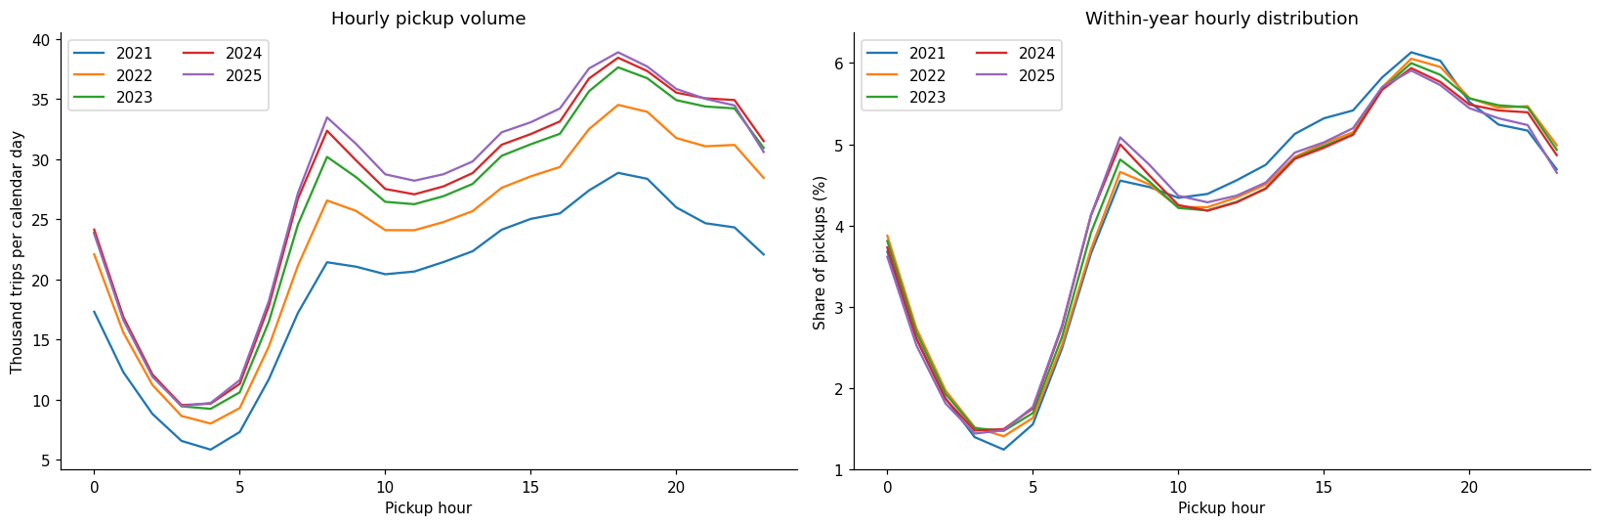

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for year, g in hourly.groupby("year"):
    h = g.groupby("hour").agg(trips=("trips", "sum"), days=("days", "sum"))
    axes[0].plot(h.index, h.trips / h.days / 1e3, label=str(year))
    axes[1].plot(h.index, h.trips / h.trips.sum() * 100, label=str(year))
axes[0].set(
    title="Hourly pickup volume",
    xlabel="Pickup hour",
    ylabel="Thousand trips per calendar day",
)
axes[1].set(
    title="Within-year hourly distribution",
    xlabel="Pickup hour",
    ylabel="Share of pickups (%)",
)
for ax in axes:
    ax.legend(ncol=2)
finish(fig, "04_hourly_pickup_profiles")


### Map the weekday and hour pattern
Heatmaps share a common scale, so differences in color represent comparable volumes across years.


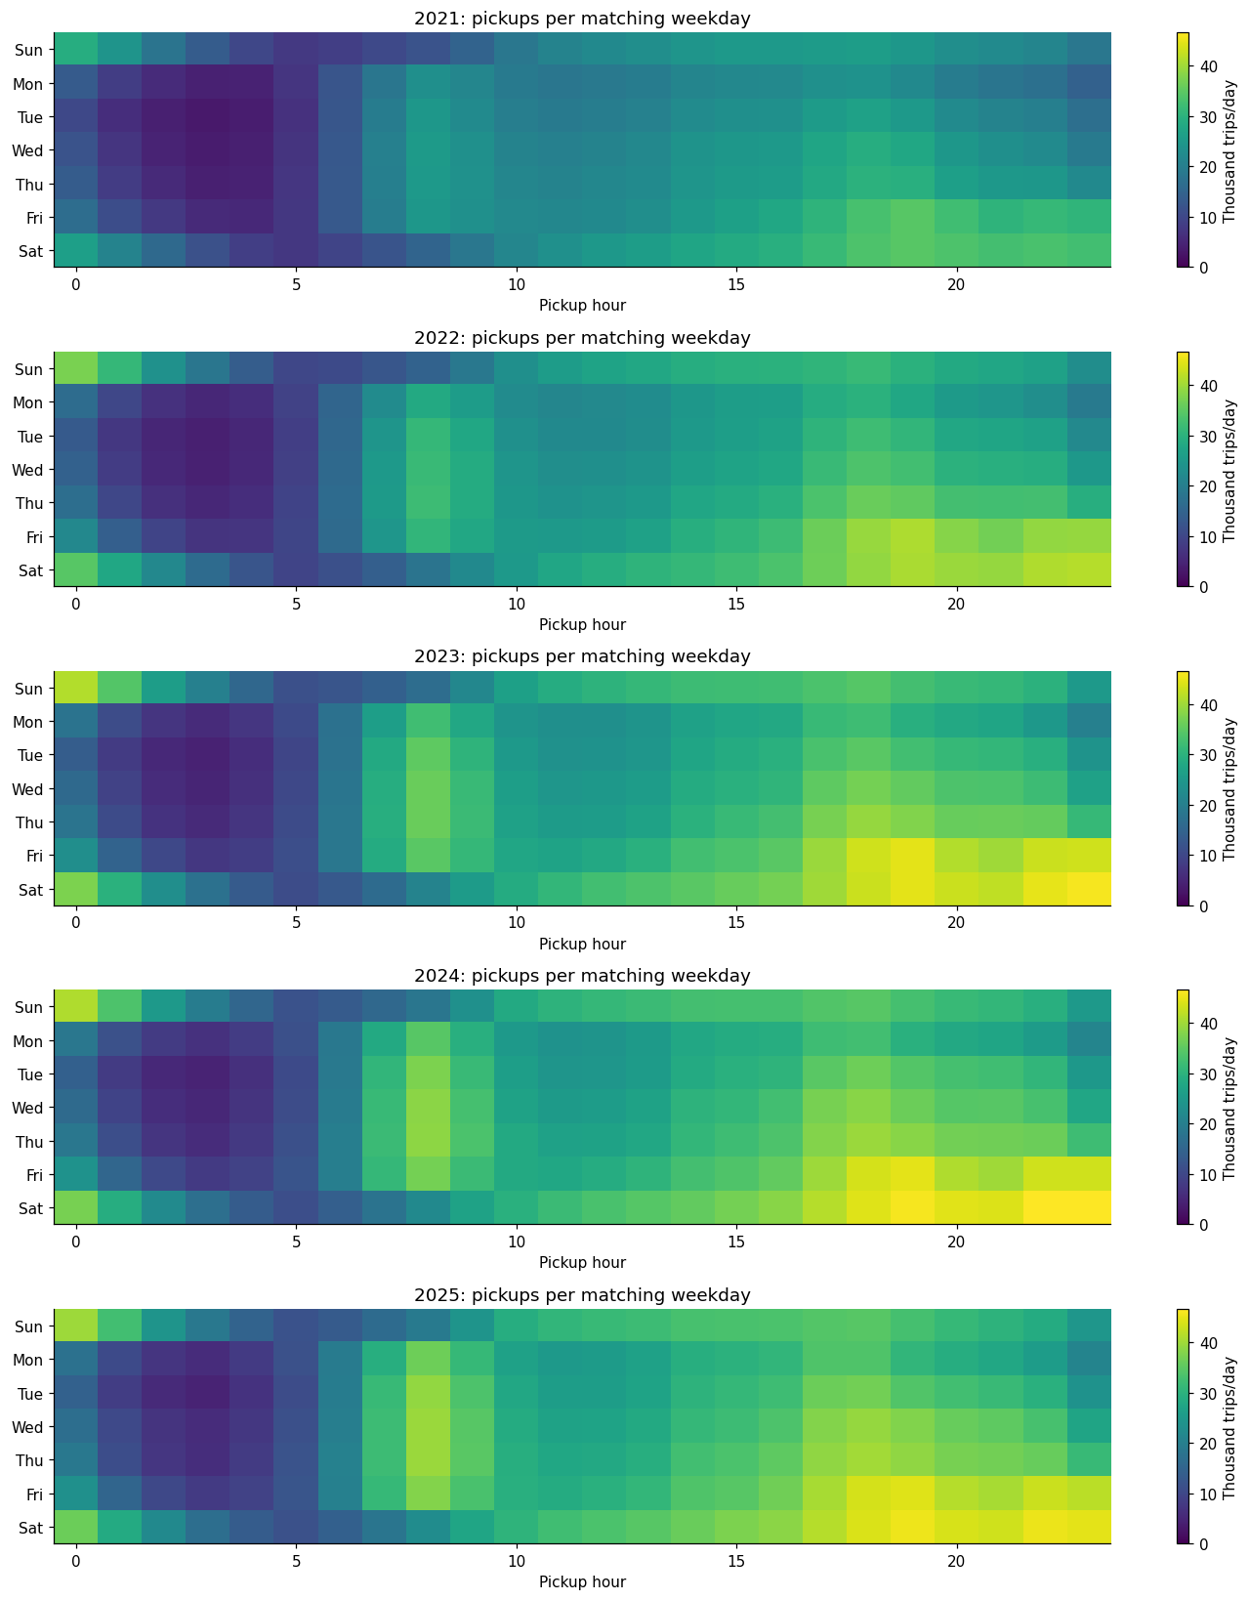

In [7]:
years = sorted(hourly.year.unique())
fig, axes = plt.subplots(len(years), 1, figsize=(13, 3 * len(years)), squeeze=False)
vmax = hourly.trips_per_day.max() / 1e3
for ax, year in zip(axes.flat, years):
    matrix = (
        hourly[hourly.year == year].pivot(
            index="dow", columns="hour", values="trips_per_day"
        )
        / 1e3
    )
    im = ax.imshow(matrix, aspect="auto", vmin=0, vmax=vmax, cmap="viridis")
    ax.set(
        title=f"{year}: pickups per matching weekday",
        xlabel="Pickup hour",
        yticks=range(7),
        yticklabels=["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"],
    )
    fig.colorbar(im, ax=ax, label="Thousand trips/day")
finish(fig, "04_weekday_hour_heatmaps")


### Compare monthly totals and calendar-day averages
Totals vary with both demand and month length. Dividing by observed calendar days separates those two effects.


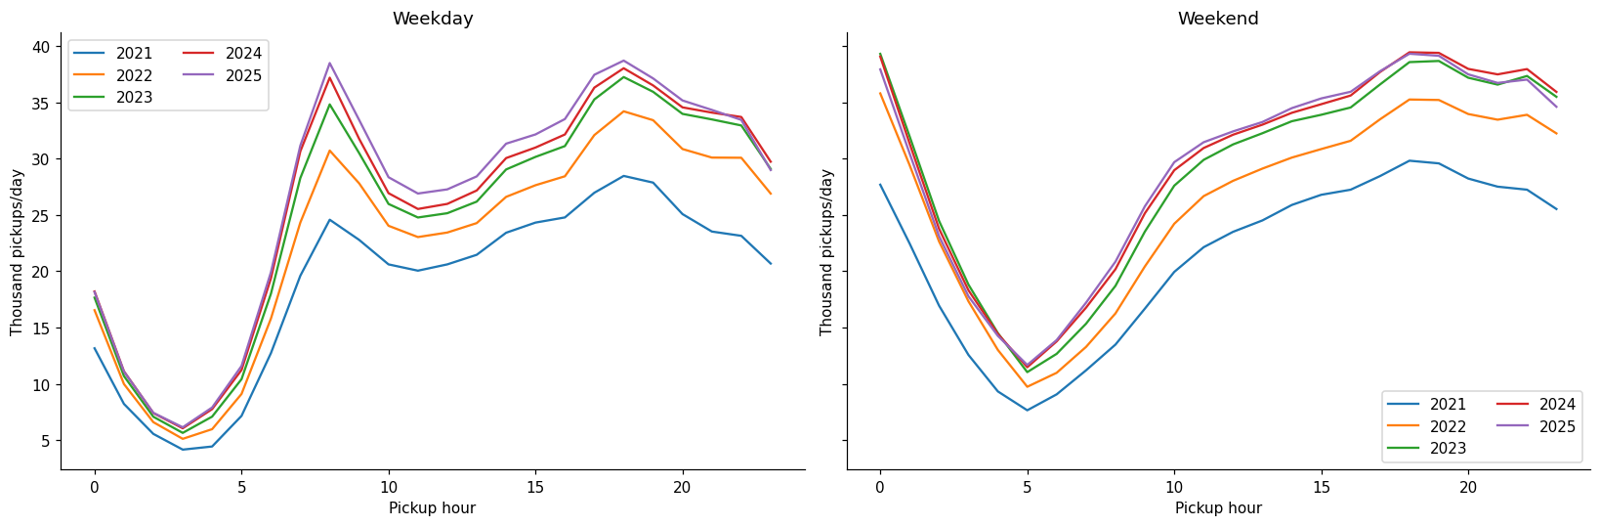

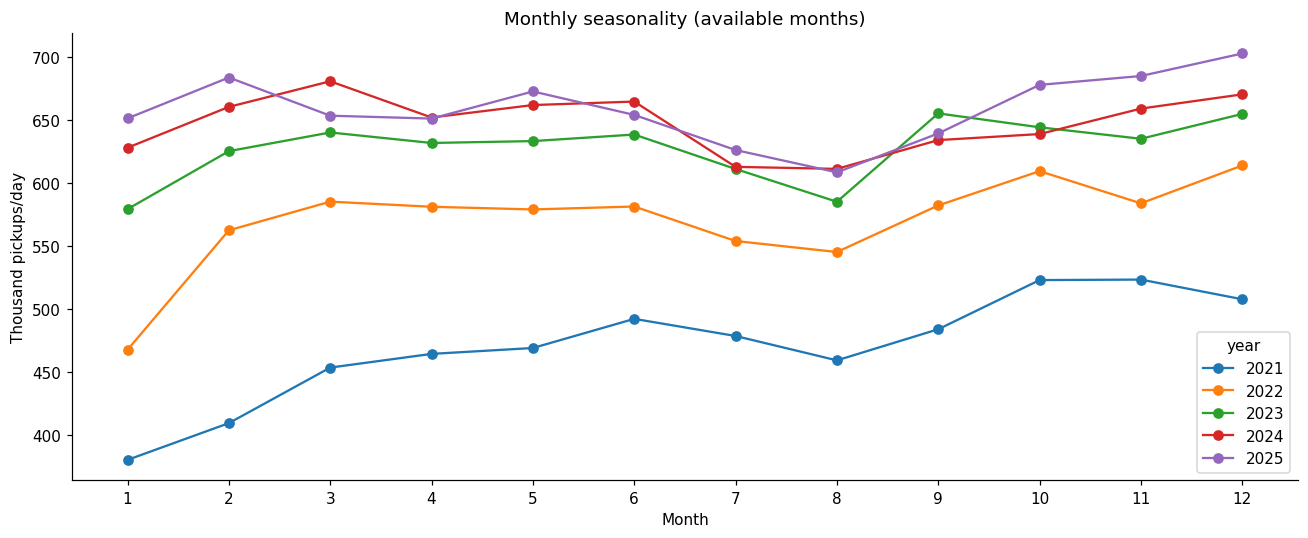

In [8]:
week = hourly.assign(day_type=np.where(hourly.dow.isin([0, 6]), "Weekend", "Weekday"))
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, kind in zip(axes, ["Weekday", "Weekend"]):
    for year, g in week[week.day_type == kind].groupby("year"):
        h = g.groupby("hour").agg(trips=("trips", "sum"), days=("days", "sum"))
        ax.plot(h.index, h.trips / h.days / 1e3, label=str(year))
    ax.set(title=kind, xlabel="Pickup hour", ylabel="Thousand pickups/day")
    ax.legend(ncol=2)
finish(fig, "04_weekday_weekend_profiles")
monthly = daily.groupby(["year", "month"]).agg(
    trips=("trips", "sum"), days=("date", "nunique")
)
monthly["trips_per_day"] = monthly.trips / monthly.days
fig, ax = plt.subplots()
monthly.trips_per_day.unstack("year").div(1e3).plot(ax=ax, marker="o")
ax.set(
    title="Monthly seasonality (available months)",
    xlabel="Month",
    ylabel="Thousand pickups/day",
    xticks=range(1, 13),
)
finish(fig, "04_monthly_seasonality")


## Findings to record

### Demand growth and within-year variation
All 60 pickup months from 2021–2025 passed the notebook's key/date/count checks. Calendar-day normalization accounts for unequal month/year length; 2024 has 366 days. Cleaned totals describe completed observed trips across recorded HVFHV platforms.

| Year | Pickups (millions) | Average daily pickups | Lowest / highest daily-average month |
|---|---:|---:|---|
| 2021 | 171.76 | 470,575 | 01 / 11 |
| 2022 | 208.11 | 570,175 | 01 / 12 |
| 2023 | 229.01 | 627,418 | 01 / 09 |
| 2024 | 236.95 | 647,401 | 08 / 03 |
| 2025 | 240.28 | 658,304 | 08 / 12 |

Average daily pickups increased by **39.9%** from 2021 to 2025. This is a descriptive expansion from the 2021 starting level; it does not identify the causes of recovery or growth. Monthly patterns generally weaken in summer and strengthen toward year-end, but the exact trough differs across years and the 2021 growth trend can dominate seasonality. A five-year pooled monthly mean would mix seasonal effects with that growth.

### Hourly and weekly patterns
Annual average hourly volume peaks at **18:00 in 2021**, **18:00 in 2022**, **18:00 in 2023**, **18:00 in 2024**, **18:00 in 2025**. The quietest hours are 04:00 (2021), 04:00 (2022), 04:00 (2023), 03:00 (2024), 03:00 (2025). **Saturday has the highest daily-average demand and Monday the lowest in every year.** In 2025, Saturday averages 761,875 pickups versus 572,478 on Monday (33.1% higher). The normalized hourly-share curves distinguish changes in timing from increases in total volume. Weekday/weekend profiles and weekday-hour heatmaps reveal timing differences that are obscured by daily totals; late-evening and overnight travel should be evaluated separately from daytime activity.

### Interpretation and limits
The hourly clock grid combines repeated autumn hours and includes daylight-saving transitions; apparent clock-hour irregularities are not automatically outages. Isolated low observations require source/coverage review and are not automatically replaced. These figures do not measure trip duration, unmet demand, or a causal congestion-pricing effect.
